# Results analysis: PathMNIST

Reads the PathMNIST result CSVs in `results/tables/pathmnist`, prints the results tables and saves the figures to `results/plots/pathmnist`.

PathMNIST (MedMNIST v2) has 89,996 training and 7,180 test colour images of colon pathology, 28 x 28, in 9 tissue classes. The runs use the same settings as the Fashion-MNIST notebook (10 clients, 1 local epoch, lr 0.003 for the hybrid model and 0.001 for the classical CNN). The strong-skew runs have 5 seeds (42 to 46) and the IID runs 3 seeds (the classical CNN 5).

In [1]:
import os
import re
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.ticker import MaxNLocator
from scipy import stats

%matplotlib inline

In [2]:
TABLES_DIR = "../results/tables/pathmnist"
PLOTS_DIR  = "../results/plots/pathmnist"

CLIENTS      = 10
EPOCHS       = 1
LR           = 0.003
CLASSICAL_LR = 0.001
MU           = 0.01
TARGET       = 75
MAIN_SPLITS  = ["IID", "Dirichlet α=0.5", "Dirichlet α=0.1"]

PATTERN = re.compile(r"^(classical|qfl_fedavg|qfl_fedprox_full|qfl_fedprox|qfl_weighted|qfl_fco|qfl_logitadj|qfl_twin_fco|qfl_twin|qfl_frozen|qfl_randcode|qfl_pauli)_(iid|dirichlet)_a([\d.]+)"
                     r"(?:_mu([\d.e-]+))?(?:_lam([\d.]+))?(?:_tau[\d.]+)?_c(\d+)_e(\d+)_lr([\d.e-]+)_s(\d+)\.csv$")

NAMES = {
    "qfl_fedavg":       "QFL FedAvg",
    "qfl_fedprox":      "Quantum FedProx",
    "qfl_fedprox_full": "Full FedProx",
    "qfl_weighted":     "Weighted Agg",
    "qfl_logitadj":     "Calibrated Loss",
    "qfl_fco":          "Fixed Observables",
    "qfl_pauli":        "Pauli Observables",
    "qfl_frozen":       "Random Frozen Readout",
    "qfl_randcode":     "Random Unit Codes",
    "qfl_twin":         "Classical Twin",
    "qfl_twin_fco":     "Twin + FCO",
    "classical":        "Classical FedAvg",
}
ORDER  = ["QFL FedAvg", "Quantum FedProx", "Full FedProx", "Weighted Agg", "Calibrated Loss",
          "Fixed Observables", "Pauli Observables", "Random Frozen Readout", "Random Unit Codes",
          "Classical Twin", "Twin + FCO", "Classical FedAvg"]
COLORS = {"QFL FedAvg": "#7f7f7f", "Quantum FedProx": "#d62728", "Full FedProx": "#ff7f0e",
          "Weighted Agg": "#1f77b4", "Calibrated Loss": "#8c564b", "Fixed Observables": "#9467bd",
          "Pauli Observables": "#e377c2", "Random Frozen Readout": "#bcbd22", "Random Unit Codes": "#c5b0d5",
          "Classical Twin": "#17becf",
          "Twin + FCO": "#1f4e79", "Classical FedAvg": "#2ca02c"}

os.makedirs(PLOTS_DIR, exist_ok=True)

## Load the runs

In [3]:
rows = []
for fname in sorted(os.listdir(TABLES_DIR)):
    match = PATTERN.match(fname)
    if not match:
        continue
    kind, partition, alpha, mu, lam, clients, epochs, lr, seed = match.groups()
    want_lr = CLASSICAL_LR if kind == "classical" else LR
    if int(clients) != CLIENTS or int(epochs) != EPOCHS or float(lr) != want_lr:
        continue

    df = pd.read_csv(os.path.join(TABLES_DIR, fname))
    acc = df["accuracy"] * 100
    rows.append({
        "strategy": NAMES[kind],
        "split": "IID" if partition == "iid" else f"Dirichlet α={float(alpha):g}",
        "mu": float(mu) if mu else np.nan,
        "seed": int(seed),
        "emd": df["emd"].iloc[0],
        "rounds": len(df),
        "final": acc.iloc[-1],
        "last5": acc.iloc[-5:].mean(),
        "best": acc.max(),
        "sec_per_round": df["time"].mean(),
        "curve": acc.tolist(),
    })

runs = pd.DataFrame(rows)
main = runs[runs["mu"].isna() | (runs["mu"] == MU)]
splits = main.groupby("split")["emd"].mean().sort_values().index.tolist()
strategies = [s for s in ORDER if s in set(main["strategy"])]
MAIN_SPLITS = [s for s in MAIN_SPLITS if s in splits]
print(f"Loaded {len(runs)} runs ({len(main)} in the main comparison)")

Loaded 50 runs (50 in the main comparison)


## Results table

Test accuracy (%) averaged over the last 5 rounds. When a setting has more than one seed the cell shows mean ± std over seeds, `-` means that run was not done.

In [4]:
summary = (main.groupby(["split", "strategy"])
           .agg(emd=("emd", "mean"), seeds=("seed", "nunique"), last5=("last5", "mean"),
                last5_std=("last5", "std"), final=("final", "mean"), best=("best", "mean"),
                sec_per_round=("sec_per_round", "mean"))
           .reset_index())
summary["last5_std"] = summary["last5_std"].fillna(0)
summary["split_order"] = summary["split"].map({s: i for i, s in enumerate(splits)})
summary["strategy_order"] = summary["strategy"].map({s: i for i, s in enumerate(ORDER)})
summary = (summary.sort_values(["split_order", "strategy_order"])
           .drop(columns=["split_order", "strategy_order"]).reset_index(drop=True))
summary.to_csv(os.path.join(TABLES_DIR, "summary.csv"), index=False)

print("| Split | EMD | " + " | ".join(strategies) + " |")
print("|---" * (len(strategies) + 2) + "|")
for split in splits:
    sub = summary[summary["split"] == split].set_index("strategy")
    cells = []
    for strategy in strategies:
        if strategy not in sub.index:
            cells.append("-")
        elif sub.loc[strategy, "seeds"] > 1:
            cells.append(f"{sub.loc[strategy, 'last5']:.2f} ± {sub.loc[strategy, 'last5_std']:.2f}")
        else:
            cells.append(f"{sub.loc[strategy, 'last5']:.2f}")
    print(f"| {split} | {sub['emd'].mean():.3f} | " + " | ".join(cells) + " |")

| Split | EMD | QFL FedAvg | Full FedProx | Fixed Observables | Classical Twin | Twin + FCO | Classical FedAvg |
|---|---|---|---|---|---|---|---|
| IID | 0.032 | 77.40 ± 1.88 | 75.33 ± 1.13 | 76.39 ± 0.41 | 79.48 ± 0.64 | 79.41 ± 0.83 | 81.88 ± 0.39 |
| Dirichlet α=0.1 | 1.666 | 38.36 ± 12.60 | 35.32 ± 12.35 | 37.84 ± 9.46 | 50.19 ± 10.28 | 52.76 ± 11.21 | 61.72 ± 10.28 |


Every run on its own (last 5 rounds mean, one column per seed):

In [5]:
per_seed = main.pivot_table(index=["split", "strategy"], columns="seed", values="last5")
order = [(sp, st) for sp in splits for st in strategies if (sp, st) in per_seed.index]
per_seed.loc[order].round(2).fillna("")

seed                                  42     43     44     45     46
split           strategy                                            
IID             QFL FedAvg         75.52  79.28  77.40              
                Full FedProx       74.26  75.21  76.52              
                Fixed Observables  75.96  76.79  76.42              
                Classical Twin     80.13  79.47  78.85              
                Twin + FCO         79.78  80.00  78.46              
                Classical FedAvg   81.69  82.52  81.97  81.56  81.66
Dirichlet α=0.1 QFL FedAvg         44.95  33.65  46.33  18.32  48.57
                Full FedProx       33.84  15.60  41.40  37.07  48.68
                Fixed Observables  39.07  44.27  44.62  21.53  39.72
                Classical Twin     54.86  41.05  59.26  37.29  58.48
                Twin + FCO         57.82  40.07  66.63  42.42  56.85
                Classical FedAvg   70.40  48.52  68.55   52.7  68.45

## Gain over QFL FedAvg on the same seeds

For every strategy, its last-5 accuracy minus QFL FedAvg's on the same seed. The same seed means the same client split and the same starting weights, so the difference comes from the method only. `better_on` counts the seeds where the strategy beat FedAvg, and `p_value` is a two-sided paired t-test (mean gain = 0). `wilcoxon_p` is the Wilcoxon signed-rank test on the same gains, which does not assume they are normally spread. With 8 seeds its smallest possible value is 0.0078, with 3 seeds it can never go below 0.25. Every μ is listed, so the μ sweep runs show up here too.

In [6]:
fedavg = runs[runs["strategy"] == "QFL FedAvg"].set_index(["split", "seed"])["last5"]
others = runs[~runs["strategy"].isin(["QFL FedAvg", "Classical FedAvg"])]

gain_rows = []
for (split, strategy, mu), sub in others.groupby(["split", "strategy", "mu"], dropna=False):
    gain = (sub.set_index("seed")["last5"] - fedavg.loc[split]).dropna()
    gain_rows.append({
        "split": split,
        "strategy": strategy,
        "mu": mu,
        "seeds": len(gain),
        "mean_gain": gain.mean(),
        "std": gain.std(),
        "better_on": f"{(gain > 0).sum()}/{len(gain)}",
        "p_value": stats.ttest_1samp(gain, 0).pvalue if len(gain) > 1 else np.nan,
        "wilcoxon_p": stats.wilcoxon(gain).pvalue if len(gain) > 1 else np.nan,
    })

gains = pd.DataFrame(gain_rows)
gains["split_order"] = gains["split"].map({s: i for i, s in enumerate(splits)})
gains["strategy_order"] = gains["strategy"].map({s: i for i, s in enumerate(ORDER)})
gains = (gains.sort_values(["split_order", "strategy_order", "mu"])
         .drop(columns=["split_order", "strategy_order"]).reset_index(drop=True))
gains.to_csv(os.path.join(TABLES_DIR, "paired_gains.csv"), index=False)

gains.round({"mean_gain": 2, "std": 2, "p_value": 4, "wilcoxon_p": 4}).fillna("")

,split,strategy,mu,seeds,mean_gain,std,better_on,p_value,wilcoxon_p
0,IID,Full FedProx,0.01,3,-2.07,1.74,0/3,0.1753,0.2500
1,IID,Fixed Observables,,3,-1.01,1.47,1/3,0.3567,0.5000
2,IID,Classical Twin,,3,2.09,2.28,3/3,0.2539,0.2500
3,IID,Twin + FCO,,3,2.01,1.96,3/3,0.2167,0.2500
4,Dirichlet α=0.1,Full FedProx,0.01,5,-3.04,13.95,2/5,0.6513,0.8125
5,Dirichlet α=0.1,Fixed Observables,,5,-0.52,7.71,2/5,0.8872,1.0000
6,Dirichlet α=0.1,Classical Twin,,5,11.83,4.45,5/5,0.0040,0.0625
7,Dirichlet α=0.1,Twin + FCO,,5,14.39,7.62,5/5,0.0134,0.0625


Rounds until the mean accuracy curve (over seeds) first reaches the target, blank means it never did:

In [7]:
reach = {}
for (split, strategy), sub in main.groupby(["split", "strategy"]):
    n = min(len(c) for c in sub["curve"])
    mean_curve = np.mean([c[:n] for c in sub["curve"]], axis=0)
    hit = np.where(mean_curve >= TARGET)[0]
    reach[(split, strategy)] = hit[0] + 1 if len(hit) else np.nan

print(f"Target = {TARGET:g}% test accuracy")
pd.Series(reach).unstack().reindex(index=splits, columns=strategies).fillna("")

Target = 75% test accuracy


,QFL FedAvg,Full FedProx,Fixed Observables,Classical Twin,Twin + FCO,Classical FedAvg
IID,12.0,17.0,12.0,8.0,5.0,3.0
Dirichlet α=0.1,,,,,,


## Accuracy per round

Mean over seeds, the shaded band is ±1 std.

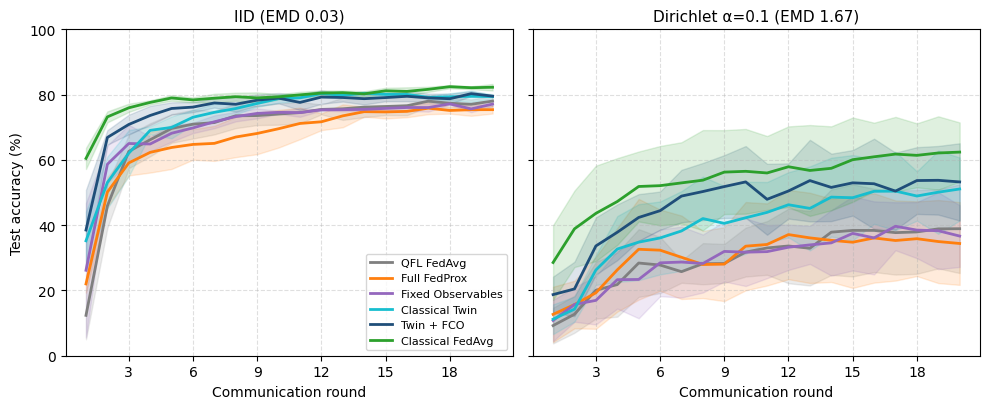

Saved: ../results/plots/pathmnist\accuracy_curves.png


In [8]:
fig, axes = plt.subplots(1, len(MAIN_SPLITS), figsize=(5 * len(MAIN_SPLITS), 4.2), sharey=True)
axes = np.atleast_1d(axes)
for ax, split in zip(axes, MAIN_SPLITS):
    for strategy in ORDER:
        sub = main[(main["split"] == split) & (main["strategy"] == strategy)]
        if sub.empty:
            continue
        n = min(len(c) for c in sub["curve"])
        curves = np.array([c[:n] for c in sub["curve"]])
        mean = curves.mean(axis=0)
        rounds = np.arange(1, n + 1)
        ax.plot(rounds, mean, label=strategy, color=COLORS[strategy], lw=2)
        if len(curves) > 1:
            std = curves.std(axis=0, ddof=1)
            ax.fill_between(rounds, mean - std, mean + std, color=COLORS[strategy], alpha=0.15)
    emd = main[main["split"] == split]["emd"].mean()
    ax.set_title(f"{split} (EMD {emd:.2f})", fontsize=11)
    ax.set_xlabel("Communication round")
    ax.xaxis.set_major_locator(MaxNLocator(integer=True))
    ax.set_ylim(0, 100)
    ax.grid(True, ls="--", alpha=0.4)
axes[0].set_ylabel("Test accuracy (%)")
axes[0].legend(fontsize=8, loc="lower right")
fig.tight_layout()

out = os.path.join(PLOTS_DIR, "accuracy_curves.png")
fig.savefig(out, dpi=200)
plt.show()
print(f"Saved: {out}")

## Accuracy vs measured non-IID level

Each point is one run. The x axis is the EMD proxy measured on that run's client split (0 = every client has the same label mix, 2 = no two clients share a class).

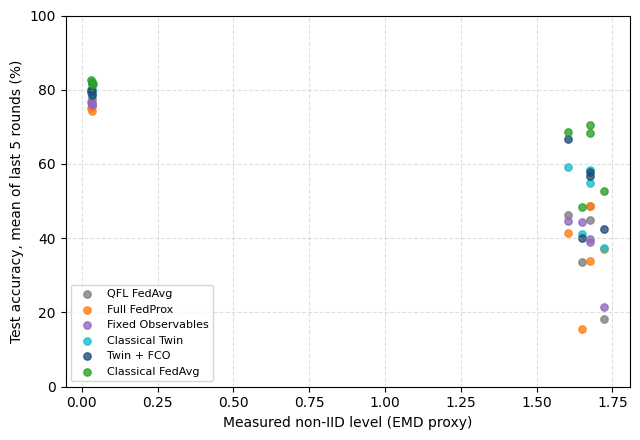

Saved: ../results/plots/pathmnist\accuracy_vs_emd.png


In [9]:
fig, ax = plt.subplots(figsize=(6.5, 4.5))
for strategy in strategies:
    sub = main[main["strategy"] == strategy]
    ax.scatter(sub["emd"], sub["last5"], label=strategy, color=COLORS[strategy], s=28, alpha=0.8)
ax.set_xlabel("Measured non-IID level (EMD proxy)")
ax.set_ylabel("Test accuracy, mean of last 5 rounds (%)")
ax.set_ylim(0, 100)
ax.grid(True, ls="--", alpha=0.4)
ax.legend(fontsize=8, loc="lower left")
fig.tight_layout()

out = os.path.join(PLOTS_DIR, "accuracy_vs_emd.png")
fig.savefig(out, dpi=200)
plt.show()
print(f"Saved: {out}")

## Strategy comparison

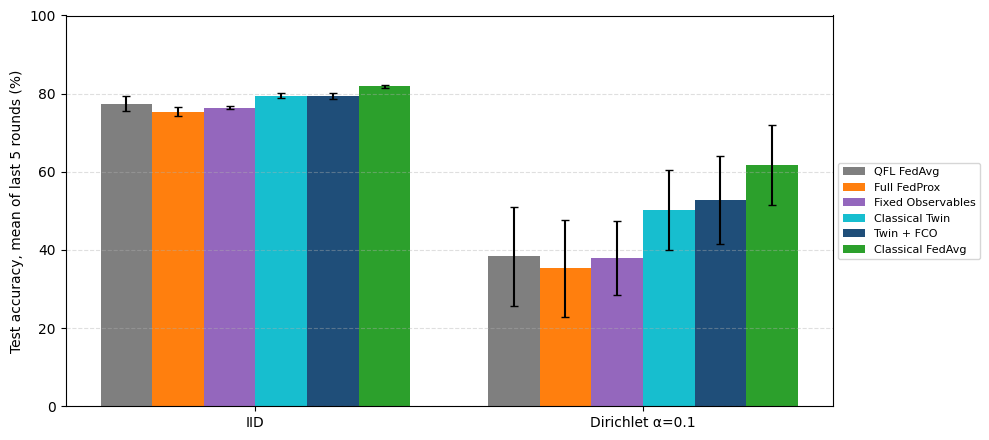

Saved: ../results/plots/pathmnist\strategy_comparison.png


In [10]:
width = 0.8 / len(strategies)
x = np.arange(len(MAIN_SPLITS))
fig, ax = plt.subplots(figsize=(10, 4.5))
for i, strategy in enumerate(strategies):
    sub = summary[summary["strategy"] == strategy].set_index("split").reindex(MAIN_SPLITS)
    ax.bar(x - 0.4 + width * (i + 0.5), sub["last5"], width, yerr=sub["last5_std"],
           label=strategy, color=COLORS[strategy], capsize=3)
ax.set_xticks(x)
ax.set_xticklabels(MAIN_SPLITS)
ax.set_ylabel("Test accuracy, mean of last 5 rounds (%)")
ax.set_ylim(0, 100)
ax.grid(axis="y", ls="--", alpha=0.4)
ax.legend(fontsize=8, loc="center left", bbox_to_anchor=(1.0, 0.5))
fig.tight_layout()

out = os.path.join(PLOTS_DIR, "strategy_comparison.png")
fig.savefig(out, dpi=200)
plt.show()
print(f"Saved: {out}")

## Is the gain specific to the quantum model?

Same-seed comparisons with the classical twin (the same model with the circuit replaced by a small classical layer). Each row is the first method minus the second on the same seeds, so a positive `mean_diff` means the first one is better.

- **Twin + FCO vs Twin**: does the fixed readout also help the classical twin?
- **FCO gain: hybrid vs twin**: the FCO gain on the hybrid model minus the FCO gain on the twin. Positive means fixing the readout helps the quantum model more than its classical twin.

The other readout ablations (random frozen head, random unit codes, Pauli observables) were run on Fashion-MNIST only, so their rows do not appear here. `p_value` is the paired t-test and `wilcoxon_p` the Wilcoxon signed-rank test (with 5 seeds its smallest possible value is 0.0625).

In [11]:
table = runs[runs["mu"].isna()].pivot_table(index=["split", "seed"], columns="strategy", values="last5")
table = table.reindex(columns=ORDER)

comparisons = {
    "FCO vs Random Frozen":     table["Fixed Observables"] - table["Random Frozen Readout"],
    "FCO vs Random Codes":      table["Fixed Observables"] - table["Random Unit Codes"],
    "Random Codes vs Frozen":   table["Random Unit Codes"] - table["Random Frozen Readout"],
    "Pauli vs FCO":             table["Pauli Observables"] - table["Fixed Observables"],
    "Twin + FCO vs Twin":       table["Twin + FCO"] - table["Classical Twin"],
    "FCO gain: hybrid vs twin": (table["Fixed Observables"] - table["QFL FedAvg"])
                                - (table["Twin + FCO"] - table["Classical Twin"]),
}

ablation_rows = []
for comparison, diff in comparisons.items():
    for split in splits:
        d = diff[diff.index.get_level_values("split") == split].dropna()
        if d.empty:
            continue
        ablation_rows.append({
            "comparison": comparison,
            "split": split,
            "seeds": len(d),
            "mean_diff": d.mean(),
            "std": d.std(),
            "positive_on": f"{(d > 0).sum()}/{len(d)}",
            "p_value": stats.ttest_1samp(d, 0).pvalue if len(d) > 1 else np.nan,
            "wilcoxon_p": stats.wilcoxon(d).pvalue if len(d) > 1 else np.nan,
        })

ablation = pd.DataFrame(ablation_rows)
ablation.to_csv(os.path.join(TABLES_DIR, "readout_ablations.csv"), index=False)
ablation.round({"mean_diff": 2, "std": 2, "p_value": 4, "wilcoxon_p": 4}).fillna("")

,comparison,split,seeds,mean_diff,std,positive_on,p_value,wilcoxon_p
0,Twin + FCO vs Twin,IID,3,-0.07,0.52,1/3,0.8297,1.0000
1,Twin + FCO vs Twin,Dirichlet α=0.1,5,2.57,3.87,3/5,0.2117,0.3125
2,FCO gain: hybrid vs twin,IID,3,-0.94,1.93,1/3,0.4904,0.7500
3,FCO gain: hybrid vs twin,Dirichlet α=0.1,5,-3.09,8.71,1/5,0.4717,0.6250
